/Users/juliomorales/Library/CloudStorage/GoogleDrive-juliomorales1823@gmail.com/My Drive/Graduate School/Research/Projects/Helioseismology/Vesa_2025/Code/diagnostic_diagram/diagnostic_diagram_functions.py:186: RuntimeWarning: divide by zero encountered in scalar power
  c0 = (4*self.H**2)**(-1) + kh**2 - (p_gamma*g_gamma + (omega*self.tau*self.gamma)**2*p1*g1) * (p_gamma**2 + (omega*self.tau*self.gamma)**2*p1**2)**(-1)
/Users/juliomorales/Library/CloudStorage/GoogleDrive-juliomorales1823@gmail.com/My Drive/Graduate School/Research/Projects/Helioseismology/Vesa_2025/Code/diagnostic_diagram/diagnostic_diagram_functions.py:186: RuntimeWarning: invalid value encountered in scalar multiply
  c0 = (4*self.H**2)**(-1) + kh**2 - (p_gamma*g_gamma + (omega*self.tau*self.gamma)**2*p1*g1) * (p_gamma**2 + (omega*self.tau*self.gamma)**2*p1**2)**(-1)
/Users/juliomorales/Library/CloudStorage/GoogleDrive-juliomorales1823@gmail.com/My Drive/Graduate School/Research/Projects/Helioseismology/Vesa_2025/Cod

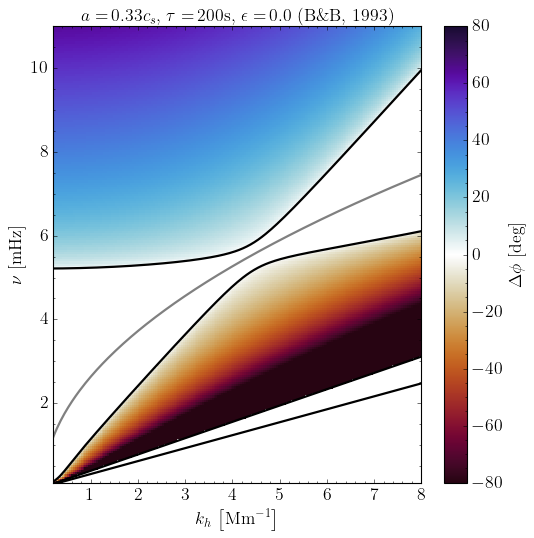

In [1]:
# Import the relevant libraries
import diagnostic_diagram_config as dd_config
import diagnostic_diagram_functions as dd_funcs
import numpy as np
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import matplotlib
import cmasher as cmr
from math import pi
from joblib import Parallel, delayed
from astropy.visualization import ZScaleInterval
from astropy.io import fits
from matplotlib import rc

# Create figure features
cmap_name = cmr.fusion
frequency_label = r'$\nu\,\left[\mathrm{mHz}\right]$'
wavenumber_label  = r'$k_{h}\,\left[\mathrm{Mm}^{-1}\right]$'
colorbar_label_kz = r'$k_{z}\,\left[\mathrm{km}^{-1}\right]$'
colorbar_label_phase = r'$\Delta\phi\,\left[\mathrm{deg}\right]$'

tex_fonts = {   "text.usetex": True,
                "font.family": "serif",
                 "font.serif": "Times New Roman",
             "axes.labelsize": 16,
                  "font.size": 16,
            "legend.fontsize": 14,
            "xtick.labelsize": 16,
            "ytick.labelsize": 16,
             "axes.titlesize": 16,
            "xtick.direction": "in",
            "ytick.direction": "in",
             "legend.frameon": True,
          "legend.framealpha": 0.8,
"axes.formatter.use_mathtext": True,
            "lines.linewidth": 2,
        "ytick.minor.visible": True,
        "xtick.minor.visible": True,
                "savefig.dpi": 300,
             "pcolor.shading": "auto",
           "figure.facecolor": "white"}

# Update matplotlib settings
plt.style.use("classic")
matplotlib.rcParams.update(tex_fonts)
rc("mathtext", **{"default": "regular"})

# Define grids
kh = np.linspace(0, 8, 200)*1e-3  # km^-1
omega = np.linspace(0, 11, 200)*2*pi*1e-3 # rad/s
kh_grid, omega_grid = np.meshgrid(kh, omega)  # km^-1, rad/s

# Intialize the diagnostic diagram
params = dd_config.params
model  = 'bunte1993'
diagram_class = dd_funcs.DiagnosticDiagram(kh_grid, omega_grid, params[model])

# Conversion factors
rad_to_mHz = (2*pi)**(-1)*1e3  # rad/s to mHz
inv_km_to_Mm = 1e3  # km^-1 to Mm^-1

# Calculate the bounds where kz^2 < 0 and calculate kz
nu = np.array(Parallel(n_jobs = -1, backend = 'loky')(delayed(diagram_class.omega_solve)(i) for i in kh))*rad_to_mHz
kz = np.stack(Parallel(n_jobs = -1, backend = 'loky')(delayed(diagram_class.kz_solve)(i) for i in kh), axis = 1)

# Calculate grids and f-mode dispersion for plotting
kh_plot  = kh_grid*inv_km_to_Mm # Mm^-1
nu_plot  = omega_grid*rad_to_mHz  # mHz
fmode_nu = diagram_class.fmode_dispersion()*rad_to_mHz

# Subtract mode contamination
if (model == 'nc2009'):
    evan_indices = np.nonzero((nu_plot >= (nu[:, 1])) & (nu_plot <= (nu[:, 2])))
    kz[:, :, 0][evan_indices] = 0.0

# Color the AGWs red
agw_indices = np.nonzero(nu_plot < fmode_nu)
kz[:, :, 0][agw_indices]  = -kz[:, :, 0][agw_indices]

# Calculate the corresponding phase speed and phase difference using list comprehensions per kz-mode
v_phase = [diagram_class.phase_speed(omega_grid, kz[:, :, n]) for n in range(params[model]['kz_order'])]  # km/s
delta_phi = [diagram_class.phase_difference(omega_grid, v_phase[n], dd_config.dz) for n in range(params[model]['kz_order'])]  # rad

# Plot the diagnostic diagram
interval = ZScaleInterval()

# Plot the phase differences
for i in range(0, params[model]['kz_order']):
    phase_difference = np.nan_to_num(delta_phi[i]*180*pi**(-1), nan = 0.0, posinf=0.0, neginf=0.0) # degrees
    if np.all(np.isclose(phase_difference, 0.0, rtol=1e-09, atol=1e-09)):
        plt.close()
        continue
    # Make the plot
    plt.figure(figsize=(7, 7))
    plt.plot(kh_plot[0], fmode_nu, 'gray')
    if (model == 'nc2009') or (model == 'bunte1993'):
        plt.plot(kh_plot[0], kh*(dd_config.ax*rad_to_mHz), color='black', linestyle='-')
    vmin, vmax = -80, 80
    plt.pcolormesh(kh_plot, nu_plot, phase_difference, cmap=cmr.fusion, shading="auto", norm=mcolors.TwoSlopeNorm(vmin=vmin, vcenter=0.0, vmax=vmax), rasterized=True)
    plt.colorbar(label=colorbar_label_phase)
    for j in range(0, params[model]['omega_order']):
        plt.plot(kh_plot[0], nu[:, j], 'k-', markersize=3)
    plt.title(f'Diagnostic Diagram for {diagram_class.model.upper()}')
    plt.xlabel(wavenumber_label)
    plt.ylabel(frequency_label)
    plt.xlim(0.2, np.max(kh_plot))
    plt.ylim(0.1, np.max(nu_plot))
    plt.tight_layout()
    plt.title(params[model]['title'])
    plt.show()
    break  # Remove this line to plot all kz modes

# for i in range(0, params[model]['kz_order']):
#     kz_i = kz[:, :, i]
#     if np.all(np.isclose(kz_i, 0.0, rtol=1e-09, atol=1e-09)):
#         plt.close()
#         continue
#     # Plot the kz_grids
#     plt.figure(figsize=(7, 7))
#     plt.plot(kh_plot[0], fmode_nu, 'gray')
#     if (model == 'nc2009') or (model == 'bunte1993'):
#         plt.plot(kh_plot[0], kh*(config.ax*rad_to_mhz, color='green', linestyle='-')
#     vmin, vmax = interval.get_limits(kz_i)
#     plt.pcolormesh(kh_plot, nu_plot, kz_i, cmap='hot', shading="auto", vmin=vmin, vmax=vmax, rasterized=True)
#     plt.colorbar(label=colorbar_label_kz)
#     for j in range(0, params[model]['omega_order']):
#         plt.plot(kh_plot[0], nu[:, j], 'k*', markersize=3)
#     plt.title(f'Diagnostic Diagram for {diagram_class.model.upper()}')
#     plt.xlabel(wavenumber_label)
#     plt.ylabel(frequency_label)
#     plt.xlim(0.2, np.max(kh_plot))
#     plt.ylim(0.1, np.max(nu_plot))
#     plt.tight_layout()
#     plt.title(params[model]['title'])
#     plt.show()

In [2]:
# def o(omega, kh):

#     # Full 3D MHD dispersion relation
#     c6 = 1
#     c5 = 0
#     c4 = -a**2*kh**2*sin(theta)**2*cos(phi)**2 - a**2*kh**2 - cs**2*kh**2 - wac**2
#     c3 = 0
#     c2 = N**2*cs**2*kh**2 + a**4*kh**4*sin(theta)**2*cos(phi)**2 + 2*a**2*cs**2*kh**4*sin(theta)**2*cos(phi)**2 + a**2*kh**2*wac**2*sin(phi)**2*sin(theta)**2 + a**2*kh**2*wac**2*sin(theta)**2*cos(phi)**2 + a**2*kh**2*wac**2*cos(theta)**2
#     c1 = 0
#     c0 = -N**2*a**2*cs**2*kh**4*sin(theta)**2*cos(phi)**2 - a**4*cs**2*kh**6*sin(theta)**4*cos(phi)**4 - a**4*kh**4*wac**2*sin(theta)**2*cos(phi)**2*cos(theta)**2

#     # # Magnetoacoustic NO Stratification
#     # c6 = 0
#     # c5 = 0
#     # c4 = 1
#     # c3 = 0
#     # c2 = -a**2*kh**2 - cs**2*kh**2
#     # c1 = 0
#     # c0 = a**2*cs**2*kh**4*sin(theta)**2*cos(phi)**2

#     # # Magnetoacoustic w stratification and no alfven waves
#     # c6 = 0
#     # c5 = 0
#     # c4 = 1
#     # c3 = 0
#     # c2 = -a**2*kh**2 - cs**2*kh**2 - wac**2
#     # c1 = 0
#     # c0 = N**2*cs**2*kh**2 + a**2*cs**2*kh**4*sin(theta)**2*cos(phi)**2 + a**2*kh**2*wac**2*cos(theta)**2

#     # # Alfven Waves
#     # c6 = 0
#     # c5 = 0
#     # c4 = 0
#     # c3 = 0
#     # c2 = 1
#     # c1 = 0
#     # c0 = -a**2*kh**2*sin(theta)**2*cos(phi)**2

#     # Compute the polynomial
#     f = c6*omega**6 + c5*omega**5 + c4*omega**4 + c3*omega**3 + c2*omega**2 + c1*omega + c0

#     return f

In [3]:
# kz_slow = np.real(((omega_grid**2 - wac**2*(cos(theta))**2)**(0.5)/(cs*cos(theta))) - tan(theta)*cos(phi)*kh_grid)
# kz_fast = np.imag(sqrt(omega_grid.astype('complex')**2/a**2 - kh_grid.astype('complex')**2))
# kz_alf = np.real((omega_grid.astype('complex')*(cos(theta))**(-1)/a)*(1 - ((wac**2)/(omega_grid.astype('complex')**2 - wac**2*(cos(theta))**2))*(((sin(theta))**2*(sin(phi))**2)/(1 + (tan(theta))**2*(cos(phi))**2)))**(0.5) - tan(theta)*cos(phi)*kh_grid.astype('complex'))

In [4]:
# # Load the data
# data = np.load('/Users/juliomorales/Research/Projects/Vesa_2024/Data/phase_coherence/RunningDiff.Coherence.vel.fe5434_k7699.npz')
# coherence = dict(data)['azim_cohr']


# # Create figure features
# fontsize = 15
# frequency_label = r'$\nu\,\left[\mathrm{mHz}\right]$'
# wavenumber_label = r'$k_{h}\,\left[\mathrm{Mm}^{-1}\right]$'
# colorbar_label = r'$\Delta\phi\,\left[\mathrm{deg}\right]$'
# cmap_name = cmr.fusion
    
# # Min and Max scaling for colorbar
# vmin = -20
# vmax = 80

# # Rotate phase by 90 degrees
# coherence = np.fliplr(np.rot90(coherence, k = 3))

# # Make the plot
# plt.rcParams.update({'font.size': fontsize})
# plt.figure(figsize = (7, 7))
# plt.imshow(coherence, cmap = cmr.freeze , origin='lower',  aspect = 'auto', rasterized = True)
# plt.xlabel(wavenumber_label)
# plt.ylabel(frequency_label)
# plt.colorbar(label = colorbar_label)
# plt.ylim(0, 150)
# # plt.xlim(0, 7)
# plt.legend(loc = 'best')
# plt.tight_layout()
# plt.show()

# import spectral_analysis
# from configparser import ConfigParser
# import astropy.io.fits as fits
# from astropy.io import ascii


# # Config file holds information for each dataset
# config_object = ConfigParser()
# config_object.read("/Users/juliomorales/Library/CloudStorage/GoogleDrive-juliomorales1823@gmail.com/My Drive/Graduate School/Research/Projects/Helioseismology/Vesa_2025/Code/J_AGW_Magnetic_Field_Effects/theoretical_diagnostic_diagram/AGWs_config.ini")

# # Dataset -- 25Apr2019, 26Apr2019, 06May2019, 08May2019, 09May2019
# date = "04252019"
# written_date = "25Apr2019"

# # Grab the location and plate scale information associated with chosen date
# date_image_information = config_object[date]

# # Data directory
# data_dir = "/Users/juliomorales/Library/CloudStorage/GoogleDrive-juliomorales1823@gmail.com/My Drive/Graduate School/Research/Projects/Helioseismology/Vesa_2025/Data/" 

# # Model atmosphere of the Sun
# model_atm_data = ascii.read(data_dir + "CSM_A.dat")

# # Determine which file type to grab -- intensity versus velocity
# fname_type_dict = {0: "int", 1: "vel"}
# fname_type = fname_type_dict.get(1)

# # Choose spectral diagnostics -- HMIcont, HMIdop, fe7090, k7699, fe5434, ca8542 -- all [km/s]
# spectral_line_higher = "k7699" # line that forms "higher" in the atmosphere
# spectral_line_lower = "fe5434" # line that forms "lower" in the atmosphere

# # File names
# magnetogram_file = data_dir + written_date + '/' + "%s.HMImag.ibis.aligned.fits"%(written_date)
# higher_line_file = data_dir + written_date + '/' + "%s.ibis.to.hmi.%s.%s.fits"%(written_date,fname_type,spectral_line_higher)

# if spectral_line_lower == "HMIdop":
#     lower_line_file = (
#         data_dir + written_date + '/' + "%s.%s.ibis.aligned.fits"%(written_date,spectral_line_lower)
#     )
# else:
#     lower_line_file = data_dir + written_date + '/' + "%s.ibis.to.hmi.%s.%s.fits"%(written_date,fname_type,spectral_line_lower)


# print("Reading in the following FITs files:")
# print(lower_line_file,"\n", higher_line_file)
# print("\n")

# # Spectral Line 1
# if spectral_line_lower == "HMIdop":
#     # HMIdop -- need to multiply by 1e-4 to get [km/s]
#     lower_line = fits.open(lower_line_file)[0].data * 1e-4
# else:
#     lower_line = fits.open(lower_line_file)[0].data

# lower_line = np.transpose(lower_line, (1, 2, 0))
# # lower_line = np.diff(lower_line,axis=-1)
# lower_line -= np.mean(lower_line)

# # Spectral Line 2
# higher_line = fits.open(higher_line_file)[0].data
# higher_line = np.transpose(higher_line, (1, 2, 0))
# higher_line -= np.mean(higher_line)

# distance = 147.1e6  # Earth-Sun distance in km
# convert_arcseconds_to_Mm = spectral_analysis.conversion_arcseconds_to_Mm(distance) # scaling for arcsec into Mm

# # Spatial sampling [arcsec/pixel]
# dx = float(date_image_information["dx"])

# # Cadence of data [s]
# dt = float(date_image_information["dt"])  

# # Nyquist wavenumber [1/arcsec]
# kx = pi / dx

# print("Nyquist wavnumber is %s 1/arcsec" % kx)
# print("Nyquist wavnumber is %s 1/Mm" % (kx / convert_arcseconds_to_Mm))
# print("Nyquist wavnumber is %s 1/km" % ((kx / convert_arcseconds_to_Mm) / 1000))

# # Nyquist frequency/angular frequency [rad/s]
# omega = pi / dt

# # Nyquist frequency/cyclic frequency [Hz]
# v = omega / (2 * pi)
# frq = v * 1000  # [mHz]
# print("Nyquist frequency is %s mHz" % frq)

# # Starting time
# start = 0
# # Duration of data -- length of time series
# end_time = higher_line.shape[-1]
# # Spatial length of data -- x and y... Ideally should be the same value (crop data cube if not)
# end_space = higher_line.shape[0]

# # Mid time and space
# mid_time = end_time // 2
# mid_space = end_space // 2

# print("The middle time is %s and the end time is %s " % (mid_time, end_time))

# # Field of view [arcsec]
# fov = dx * end_space 
# print("FOV is %s arcseconds" % (fov))

# # Horizontal wavenumber 
# horizontal_array = np.linspace(0.0, kx, int(mid_space), endpoint=True)  # [1/arcsec]
# kx_km = horizontal_array / convert_arcseconds_to_Mm / 1000  # [1/km]

# # Field of view array
# arcsecond_length_array = np.linspace(0.0, fov, int(end_space), endpoint=True)
# # Meshgrid for field of view (if needed)
# arcx, arcy = np.meshgrid(arcsecond_length_array, arcsecond_length_array)

# print("The FOV meshgrid has the following shape: ", arcx.shape)

# # Frequency [mHz]
# freq_array = np.linspace(0.0, frq, int(mid_time), endpoint=True)
# print("The three first frequencies are ", freq_array[0:4])
# print("The length of the frequency array is", len(freq_array))

# # Meshgrid for data
# NU, KH = np.meshgrid(freq_array, horizontal_array)
# NU

In [5]:
# from scipy.interpolate import interp2d

# # Create interpolation function
# coh_f = interp2d(kx_km, freq_array[:419], coherence, kind = 'quintic')

# # Interpolate onto new grid
# coh_intp = coh_f(kx, dd.nu_plot[:,0])

# # Load the data
# data = np.load('/Users/juliomorales/Downloads/RunningDiff.PhaseDifference.vel.k7699_fe7090.npz')
# data_phase = dict(data)['azim_phase_deg']

# # Create interpolation function
# phase_f = interp2d(kx_km, freq_array[:419], np.swapaxes(data_phase, 0, 1), kind = 'quintic')

# # Interpolate onto new grid
# phase_intp = phase_f(dd.kx, dd.nu_plot[:,0])

# # Make the plot
# plt.rcParams.update({'font.size': fontsize})
# plt.figure(figsize = (7, 7))
# plt.pcolormesh(np.real(dd.kh_plot), np.real(dd.nu_plot), phase_intp, cmap = cmap_name, shading = "auto", norm=mcolors.TwoSlopeNorm(vmin=-20, vcenter=0.0, vmax=vmax), rasterized = True)
# # plt.plot(np.real(dd.kh_plot[0]), np.real(dd.fmode_nu), 'gray')
# plt.plot(np.real(dd.kh_plot[0]), np.real(dd.nu4), 'k*', markersize = 3)
# plt.plot(np.real(dd.kh_plot[0]), np.real(dd.nu2), 'k*', markersize = 3)
# plt.plot(np.real(dd.kh_plot[0]), np.real(dd.nu1), 'k*', markersize = 3)
# plt.plot(np.real(dd.kh_plot[0]), np.real(dd.nu3), 'k*', markersize = 3)
# plt.plot(np.real(dd.kh_plot[0]), np.real(dd.nu5), 'k*', markersize = 3)
# plt.plot(np.real(dd.kh_plot[0]), np.real(dd.nu6), 'k*', markersize = 3)
# plt.plot(np.real(dd.kh_plot[0]), np.real(dd.fmode_nu), 'gray')
# plt.plot(np.real(dd.kh_plot[0]), np.real(dd.nu1), 'k*', markersize = 3)
# plt.plot(np.real(dd.kh_plot[0]), np.real(dd.nu2), 'k*', markersize = 3)
# plt.plot(np.real(dd.kh_plot[0]), np.real(dd.nu3), 'k*', markersize = 3)
# plt.plot(np.real(dd.kh_plot[0]), np.real(dd.nu4), 'g*', markersize = 3)
# plt.plot(np.real(dd.kh_plot[0]), np.real(dd.nu5), 'b*', markersize = 3)
# plt.plot(np.real(dd.kh_plot[0]), np.real(dd.nu6), 'm*', markersize = 3)
# plt.xlim(0, 7)
# plt.ylim(0, 10)
# plt.xlabel(wavenumber_label)
# plt.ylabel(frequency_label)
# plt.colorbar(label = colorbar_label)
# # plt.legend(loc = 'best')
# plt.tight_layout()
# # plt.savefig(fig_path + 'diagnostic_diagram_vel_fe5434_k7699_mag.jpg', dpi = 300, bbox_inches = 'tight')

# plt.show()